In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print(f"✅ Podpięto katalog projektu: {PROJECT_ROOT}")


✅ Podpięto katalog projektu: /Users/michalskoczylas/Documents/studia/thesis/dane


In [2]:
from src.lightning_data import GestureDataModule

dm = GestureDataModule(batch_size=32, img_size=64)
dm.setup()
print(f"🏷️ Klasy ({dm.num_classes}): {dm.class_names}")
print(f"📸 Próbki train: {len(dm.train_dataset)} | val: {len(dm.val_dataset)}")


🏷️ Klasy (8): ['closehand', 'dislike', 'left', 'ok', 'openhand', 'right', 'shaka', 'v']
📸 Próbki train: 719 | val: 180


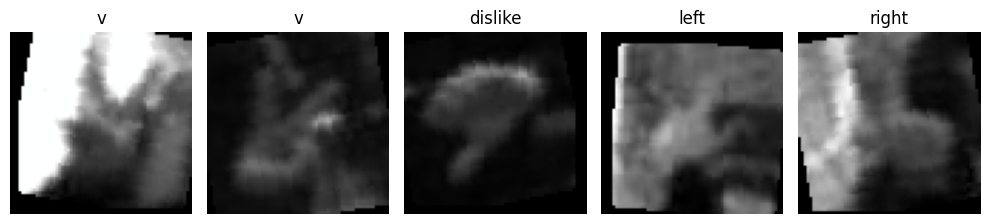

In [3]:
import matplotlib.pyplot as plt
from src.dataset import denormalize
# Pobieramy 1 batch
images, labels = next(iter(dm.train_dataloader()))
plt.figure(figsize=(10, 4))
for i in range(min(5, len(images))):
    plt.subplot(1, 5, i + 1)
    plt.imshow(denormalize(images[i]))
    plt.title(dm.class_names[labels[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [5]:
import torch.nn as nn

In [ ]:
import toch.nn as nn
from src.lightning_trainer import train_lightning

class Cnn_baseline(nn.Module):
    def __init__(self,num_classes=8):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3,32,kernel_size=3,padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32,64,kernel_size=3,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2) 
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64,num_classes)
        )
    
    def forward(self,x):
        return self.classifier(self.features(x))

model = Cnn_baseline(num_classes=8)

pl_model, trainer, dm = train_lightning(
    model = model,
    num_epochs=25,
    batch_size=32,
    lr=1e-3,
    experiment_name="cnn_baseline_1"
)

# Definicja modelu

In [6]:
from tensorboard import program
from cryptography.hazmat.primitives import padding
import pytorch_lightning as pl
import torch
import torch.nn as nn
import torchmetrics

class Baseline_cnn(pl.LightningModule):
    def __init__(self,num_classes = 8, lr=1e-3):
        super().__init__()
        self.save_hyperparameters()
        self.lr = lr


        #layers
        self.net = nn.Sequential(
            nn.Conv2d(3,32,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(64,num_classes)
        )

        self.criterion = nn.CrossEntropyLoss(),
        self.acc = torchmetrics.Accuracy(task="multiclass",num_classes=num_classes)
    
    def forward(self,x):
        return self.net(x)

    def training_step(self,batch,batch_idx):
        x, y = batch,
        logits = self(x),
        loss = self.criterion(logits,y)
        self.log("train_loss",loss,prog_bar=True)
        return loss

    def validation_steps(self,batch,batch_idx):
        x,y =batch,
        logits = self(x),
        loss = self.criterion(logits,y),
        self.acc(logits,y),
        self.log("val_loss",loss,prog_bar=True),
        self.log("val_acc",self.acc,prog_bar=True)

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(),lr=self.lr)

## Dataloader

In [9]:
from pathlib import Path
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

data_dir = Path("data/cnn_dataset")if Path("data/cnn_dataset").exists() else Path("../data/cnn_dataset")
transform = transforms.Compose([
    

    transforms.Resize((64,64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    
])

train_dataset = datasets.ImageFolder(data_dir / "train", transform=transform)
val_dataset = datasets.ImageFolder(data_dir / "val", transform=transform)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
print("Klasy:", train_dataset.classes)


Klasy: ['closehand', 'dislike', 'left', 'ok', 'openhand', 'right', 'shaka', 'v']
